# FDP API + MCP Exploration Notebook

This notebook exercises every public entry point of the Fair Districts Data Platform (FDP) API and MCP server, then visualises the results with matplotlib and D3.js.

## ⚠️ Important: where is the FDP server?

The default `FDP_BASE_URL` is `http://127.0.0.1:8001`, which only works if this notebook runs **on the same machine as the FDP server** (e.g. your WSL homelab).

- **Running locally in WSL/Jupyter?** Leave `FDP_BASE_URL = "http://127.0.0.1:8001"`.
- **Running in Google Colab?** You must change `FDP_BASE_URL` to a public URL such as:
  - A Cloudflare Tunnel URL (`https://fdp.yourdomain.com`) — see `DEPLOYMENT.md` section 2
  - A Modal + Cloudflare Worker URL — see `DEPLOYMENT.md` sections 4–5

The FDP API is file-only: there is no PostgreSQL/Supabase dependency.
`POST /api/v1/query` runs DuckDB SQL over parquet files using `read_parquet('path.parquet')`.

If you see `ConnectionRefusedError`, the notebook cannot reach the FDP server at the URL you configured.

## Fill-in parameters

All user-editable variables live in the **CONFIG** cell below. Change them, then run the cells in order.


In [16]:
# -------------------------------------------------
# CONFIG — edit these values, then run all cells
# -------------------------------------------------

# Base URL of the FDP unified API / MCP server.
#
# LOCAL WSL/JUPYTER (notebook and server on same machine):
#   FDP_BASE_URL = "http://127.0.0.1:8001"
#
# GOOGLE COLAB (notebook runs remotely; FDP must be publicly reachable):
#   FDP_BASE_URL = "https://fdp.yourdomain.com"
#
# If you get ConnectionRefusedError, this URL is wrong for where you are running.
FDP_BASE_URL = "http://127.0.0.1:8001"

# Optional secret for authenticated endpoints (POST /api/v1/query).
# Leave empty if you only want to use the MCP tools.
FDPAPI_SECRET = ""

# Which chamber to analyse: "congress", "senate", or "house".
CHAMBER = "house"

# Plan IDs. Pick IDs returned by the "List catalog" cell.
PLAN_ID = "house_enacted_24"
PLAN_A_ID = "house_enacted_24"
PLAN_B_ID = "house_enacted_2123"

# Benchmark config ID (used by benchmark_plan).
BENCHMARK_ID = "ga_house_2026_v1"

# Natural-language question for ask_question.
NLQ_QUESTION = "Which districts in the 2024 enacted house map are competitive?"

# Raw SQL query for /api/v1/query (requires FDPAPI_SECRET).
# Use read_parquet('relative/path.parquet') — there are no database tables.
SQL_QUERY = "SELECT * FROM read_parquet('election_results_vtd.parquet') LIMIT 5"

# Geo level for analyses.
GEO_LEVEL = "vtd"

print("Config loaded.")
print(f"  FDP URL: {FDP_BASE_URL}")
print(f"  Chamber: {CHAMBER}")
print(f"  Plan:    {PLAN_ID}")


Config loaded.
  FDP URL: http://127.0.0.1:8001
  Chamber: house
  Plan:    house_enacted_24


## Setup

Install only `requests` (standard on Colab; included for local notebooks).


In [17]:
import json
import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Javascript, display

# Helper for pretty-printing JSON responses
def pp(data):
    print(json.dumps(data, indent=2, default=str))

# MCP request helper
def mcp_call(method, params=None, req_id=1):
    payload = {
        "jsonrpc": "2.0",
        "id": req_id,
        "method": method,
    }
    if params is not None:
        payload["params"] = params
    url = f"{FDP_BASE_URL}/mcp"
    resp = requests.post(url, json=payload, headers={"Content-Type": "application/json"})
    resp.raise_for_status()
    return resp.json()

print("Helpers defined.")


Helpers defined.


## 1. Health check

Quick liveness check against the unified API.


In [18]:
health_url = f"{FDP_BASE_URL}/api/v1/health"
resp = requests.get(health_url)
print(f"Status: {resp.status_code}")
pp(resp.json())


Status: 200
{
  "status": "ok",
  "election_rows": 86336
}


## 2. List catalog

Discover available plans for the selected chamber.


In [19]:
catalog = mcp_call("tools/call", {
    "name": "list_catalog",
    "arguments": {"chamber": CHAMBER}
}, req_id=2)
pp(catalog)

# Store plans in a DataFrame for later visualization
catalog_text = json.loads(catalog["result"]["content"][0]["text"])
plans_df = pd.DataFrame(catalog_text["plans"].get(CHAMBER, []))
print("\nPlans DataFrame:")
display(plans_df)


{
  "jsonrpc": "2.0",
  "id": 2,
  "result": {
    "content": [
      {
        "text": "{\n  \"plans\": {\n    \"house\": [\n      {\n        \"id\": \"house_enacted_24\",\n        \"label\": \"2024 Enacted House Map\",\n        \"chamber\": \"house\",\n        \"file\": \"boundaries/house/house_enacted_24_2024update.geojson\",\n        \"app\": \"fdex\"\n      },\n      {\n        \"id\": \"house_enacted_2123\",\n        \"label\": \"State House Map, 2021\\u20132024\",\n        \"chamber\": \"house\",\n        \"file\": \"boundaries/house/house_enacted_2123_2024update.geojson\",\n        \"app\": \"fdex\"\n      },\n      {\n        \"id\": \"house_remedy_2\",\n        \"label\": \"GHDC House Remedy (2023)\",\n        \"chamber\": \"house\",\n        \"file\": \"boundaries/house/house_remedy_2.geojson\",\n        \"app\": \"fdex\"\n      },\n      {\n        \"id\": \"house_prop1_dem\",\n        \"label\": \"State House Proposal 1 (Dem)\",\n        \"chamber\": \"house\",\n        \"

,id,label,chamber,file,app
0,house_enacted_24,2024 Enacted House Map,house,boundaries/house/house_enacted_24_2024update.g...,fdex
1,house_enacted_2123,"State House Map, 2021–2024",house,boundaries/house/house_enacted_2123_2024update...,fdex
2,house_remedy_2,GHDC House Remedy (2023),house,boundaries/house/house_remedy_2.geojson,fdex
3,house_prop1_dem,State House Proposal 1 (Dem),house,boundaries/house/house_prop1_dem.geojson,fdex
4,house_prop2_rep,State House Proposal 2 (Rep),house,boundaries/house/house_prop2_rep.geojson,fdex
5,house15_census20,"State House Map, 2015–2021 (2020 Census Bounda...",house,boundaries/house/house15_census20.geojson,fdex
6,enacted_house22,GA House — Enacted 2022,house,boundaries/house/enacted_house22.geojson,map_compare
7,enacted_house22_2024update,GA House — Enacted 2022 (2024 update),house,boundaries/house/enacted_house22_2024update.ge...,map_compare
8,house15_census20,GA House — 2015 Plan (2020 Census data),house,boundaries/house/house15_census20.geojson,map_compare
9,house_enacted_2123_2024update,GA House — Enacted 2021-23 (2024 update),house,boundaries/house/house_enacted_2123_2024update...,map_compare


## 3. Analyze a single plan

Run a full demographic/partisan analysis.


In [20]:
analyze = mcp_call("tools/call", {
    "name": "analyze_plan",
    "arguments": {
        "plan_id": PLAN_ID,
        "chamber": CHAMBER,
        "geo_level": GEO_LEVEL
    }
}, req_id=3)

analyze_result = json.loads(analyze["result"]["content"][0]["text"])["result"]
summary = analyze_result["summary"]
districts = analyze_result["districts"]

print("Summary:")
pp(summary)


Summary:
{
  "n_districts": 180,
  "total_population": 10711856,
  "total_vap": 8220227,
  "dem_districts": 82,
  "rep_districts": 98,
  "dem_pct": 45.6,
  "rep_pct": 54.4,
  "competitive_districts": {
    "t_3pp": 9,
    "t_5pp": 13,
    "band_46.5_53.5": 9
  },
  "minority_districts": {
    "black": {
      "majority": 54,
      "influence": 9,
      "total": 63
    },
    "white": {
      "majority": 99,
      "influence": 32,
      "total": 131
    },
    "hispanic": {
      "majority": 1,
      "influence": 3,
      "total": 4
    },
    "minority_coalition": {
      "majority": 0,
      "influence": 0,
      "total": 0
    }
  },
  "avg_partisan_lean": 50.1
}


## 4. Compare two plans

Side-by-side district comparison.


In [21]:
compare = mcp_call("tools/call", {
    "name": "compare_plans",
    "arguments": {
        "plan_a_id": PLAN_A_ID,
        "plan_b_id": PLAN_B_ID,
        "chamber": CHAMBER,
        "geo_level": GEO_LEVEL
    }
}, req_id=4)

compare_result = json.loads(compare["result"]["content"][0]["text"])["result"]
print("Comparison keys:", list(compare_result.keys()))
pp(compare_result.get("summary", compare_result)[:200] if isinstance(compare_result, str) else compare_result.get("summary", compare_result))


Comparison keys: ['plan_a_id', 'plan_b_id', 'chamber', 'match_mode', 'district_deltas', 'summary']
{
  "n_districts_a": 180,
  "n_districts_b": 180,
  "n_renumbered": 0,
  "n_flips": 9,
  "ideal_pop_b": 59510.6
}


## 5. Benchmark a plan

Compare a plan against an ensemble benchmark.


In [22]:
benchmark = mcp_call("tools/call", {
    "name": "benchmark_plan",
    "arguments": {
        "plan_id": PLAN_ID,
        "benchmark_id": BENCHMARK_ID,
        "chamber": CHAMBER,
        "geo_level": GEO_LEVEL
    }
}, req_id=5)

benchmark_result = json.loads(benchmark["result"]["content"][0]["text"])["result"]
print("Benchmark keys:", list(benchmark_result.keys()))
pp(benchmark_result.get("summary", benchmark_result))


Benchmark keys: ['plan_id', 'benchmark_id', 'chamber', 'partisan_grade', 'competitiveness_grade', 'demographics_grade', 'overall_grade', 'pass_fail', 'details']
{
  "plan_id": "house_enacted_24",
  "benchmark_id": "ga_house_2026_v1",
  "chamber": "house",
  "partisan_grade": "N/A",
  "competitiveness_grade": "N/A",
  "demographics_grade": "N/A",
  "overall_grade": "N/A",
  "pass_fail": "N/A",
  "details": {}
}


## 6. Natural-language question

Let the NLQ layer translate a question into analysis parameters.


In [23]:
nlq = mcp_call("tools/call", {
    "name": "ask_question",
    "arguments": {"question": NLQ_QUESTION}
}, req_id=6)

nlq_result = json.loads(nlq["result"]["content"][0]["text"])
print("NLQ result type:", nlq_result.get("type"))
pp(nlq_result)


NLQ result type: error
{
  "type": "error",
  "error": "Cannot reach llama.cpp at http://127.0.0.1:8080/v1. Is llama.cpp running on Windows host at http://127.0.0.1:8080/v1? Underlying error: <urlopen error [Errno 111] Connection refused>",
  "hint": "Set AI_PROVIDER and AI_API_KEY (or LLAMA_* for llama.cpp) environment variables."
}


## 7. Raw SQL query

Requires `FDPAPI_SECRET`. Skip this cell if the secret is empty.


In [12]:
if not FDPAPI_SECRET:
    print("FDPAPI_SECRET is empty — skipping raw SQL query.")
else:
    query_url = f"{FDP_BASE_URL}/api/v1/query"
    headers = {
        "Content-Type": "application/json",
        "X-FDPAPI-Secret": FDPAPI_SECRET
    }
    resp = requests.post(query_url, json={"sql": SQL_QUERY}, headers=headers)
    resp.raise_for_status()
    query_result = resp.json()
    pp(query_result)


FDPAPI_SECRET is empty — skipping raw SQL query.


## 8. Visualise with matplotlib

Partisan lean and competitiveness of the analysed plan.


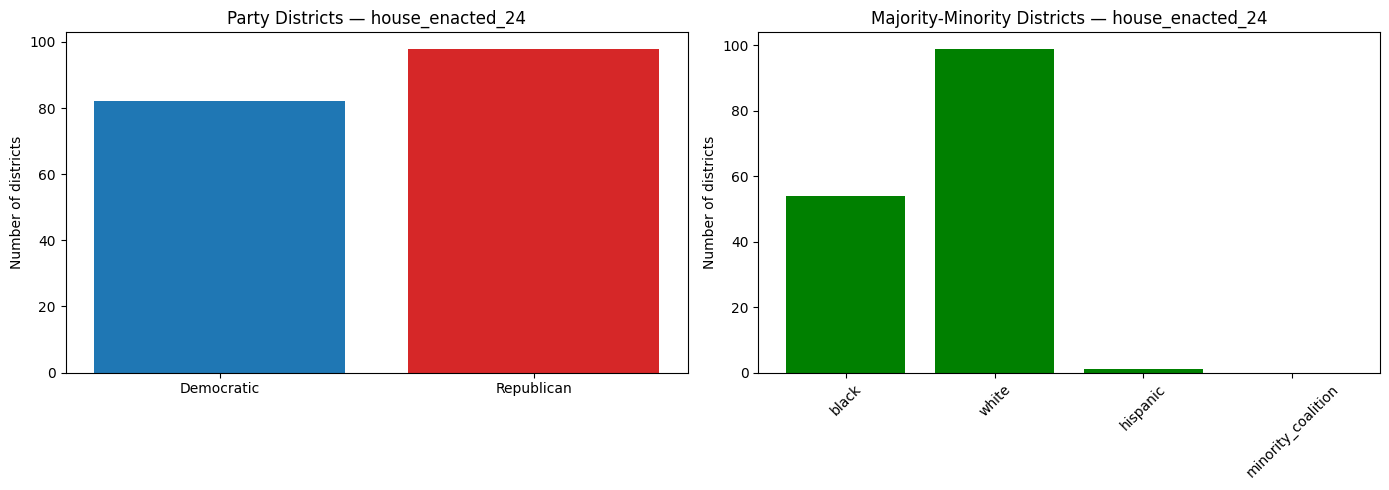

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Party breakdown
party_labels = ["Democratic", "Republican"]
party_values = [summary["dem_districts"], summary["rep_districts"]]
axes[0].bar(party_labels, party_values, color=["#1f77b4", "#d62728"])
axes[0].set_title(f"Party Districts — {PLAN_ID}")
axes[0].set_ylabel("Number of districts")

# Minority majority districts
minority = summary.get("minority_districts", {})
minority_labels = list(minority.keys())
majority_counts = [minority[g]["majority"] for g in minority_labels]
axes[1].bar(minority_labels, majority_counts, color="green")
axes[1].set_title(f"Majority-Minority Districts — {PLAN_ID}")
axes[1].set_ylabel("Number of districts")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


## 9. Visualise with D3.js

Interactive bar chart rendered in the notebook output.


In [24]:
d3_data = [
    {"label": "Dem", "value": summary["dem_districts"]},
    {"label": "Rep", "value": summary["rep_districts"]},
    {"label": "Competitive", "value": summary["competitive_districts"]["band_46.5_53.5"]},
]

html_template = r'''
<div id="d3-chart"></div>
<script src="https://d3js.org/d3.v7.min.js"></script>
<script>
  const data = __DATA__;
  const margin = {top: 20, right: 20, bottom: 30, left: 40};
  const width = 500 - margin.left - margin.right;
  const height = 300 - margin.top - margin.bottom;

  const svg = d3.select("#d3-chart")
    .append("svg")
    .attr("width", width + margin.left + margin.right)
    .attr("height", height + margin.top + margin.bottom)
    .append("g")
    .attr("transform", `translate(${margin.left},${margin.top})`);

  const x = d3.scaleBand()
    .range([0, width])
    .domain(data.map(d => d.label))
    .padding(0.2);

  svg.append("g")
    .attr("transform", `translate(0,${height})`)
    .call(d3.axisBottom(x));

  const y = d3.scaleLinear()
    .domain([0, d3.max(data, d => d.value) * 1.1])
    .range([height, 0]);

  svg.append("g")
    .call(d3.axisLeft(y));

  svg.selectAll("rect")
    .data(data)
    .join("rect")
    .attr("x", d => x(d.label))
    .attr("y", d => y(d.value))
    .attr("width", x.bandwidth())
    .attr("height", d => height - y(d.value))
    .attr("fill", d => d.label === "Dem" ? "#1f77b4" : d.label === "Rep" ? "#d62728" : "#9467bd");
</script>
'''
html = html_template.replace("__DATA__", json.dumps(d3_data))
display(HTML(html))


## 10. Export CSV for rawgraphs.io

Generate a CSV you can paste/upload into [rawgraphs.io](https://rawgraphs.io).


In [25]:
# Build a district-level CSV from the analyse_plan result
district_rows = []
for did, dinfo in districts.items():
    row = {"district": did}
    row.update(dinfo)
    district_rows.append(row)

districts_df = pd.DataFrame(district_rows)
csv_path = "/tmp/fdp_districts.csv"
districts_df.to_csv(csv_path, index=False)
print(f"CSV saved to {csv_path}")
print(f"Rows: {len(districts_df)}, Columns: {list(districts_df.columns)}")
display(districts_df.head())

# In Colab, offer a download link
from google.colab import files
files.download(csv_path)


AttributeError: 'list' object has no attribute 'items'